# 01. Исследование и проверка данных

Вариант 6. Выполняйте блокноты в порядке 01 → 02 → 03 → 04. Код этапа взят из scripts.

Период данных: 2016–2025; отличие от требуемого 2010–2025 необходимо согласовать с преподавателем.

In [1]:
from pathlib import Path
import subprocess
import sys
import os

project = Path("/content/fintech_nbk_corrected")

if not (project / ".git").exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/BEJLIKAN/fintech-nbk-rates.git",
            str(project)
        ],
        check=True
    )

os.chdir(project)

if str(project) not in sys.path:
    sys.path.insert(0, str(project))

import numpy as np
import pandas as pd
import scipy
import statsmodels.api as sm
import sklearn
import matplotlib.pyplot as plt

%matplotlib inline

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Statsmodels:", sm.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Среда готова — можно запускать вторую ячейку.")


NumPy: 2.1.3
Pandas: 2.2.3
SciPy: 1.16.3
Statsmodels: 0.15.0
Scikit-learn: 1.6.1
Среда готова — можно запускать вторую ячейку.


Библиотеки подключены
CSV-файлы в Colab:
NBK_BNS_variant6_2016_2025.csv

Нужный файл найден!
Количество строк: 120
Количество столбцов: 8

Названия столбцов:
['month', 'loan_business_pct', 'loan_households_pct', 'inflation_mom_pct', 'inflation_yoy_pct', 'base_rate_pct', 'Y_business_change_pp', 'Y_households_change_pp']
Все необходимые столбцы присутствуют
Начало периода: 2016-01
Конец периода: 2025-12
Все показатели имеют корректный числовой формат
120 последовательных месяцев
Повторных месяцев нет
Пропущенных месяцев нет
Разделение выполнено без перемешивания
Тестовая часть отложена до этапа 4


,Часть,Месяцев,"Доля, %",Начало,Конец
0,Train — обучение,84,70.0,2016-01,2022-12
1,Validation — настройка,18,15.0,2023-01,2024-06
2,Test — итоговая проверка,18,15.0,2024-07,2025-12


,Столбец,Тип,"Пропуски в train, %",Экономический смысл
0,month,datetime64[ns],0.0,Месяц наблюдения; не дата публикации
1,loan_business_pct,float64,0.0,"Ставка новых кредитов юрлицам в тенге, % годовых"
2,loan_households_pct,float64,0.0,"Ставка новых кредитов физлицам, включая ИП, % ..."
3,inflation_mom_pct,float64,0.0,"Инфляция к предыдущему месяцу, %"
4,inflation_yoy_pct,float64,0.0,"Инфляция к тому же месяцу прошлого года, %"
5,base_rate_pct,float64,0.0,"Средняя базовая ставка за календарный месяц, %..."
6,Y_business_change_pp,float64,0.0,"Изменение ставки юрлицам за месяц, п.п."
7,Y_households_change_pp,float64,0.0,"Изменение ставки физлицам за месяц, п.п."


,Показатель,Риск,Правило
0,Кредитная ставка текущего месяца,Входит в формулу текущего Y,Не включать в X текущего месяца
1,Инфляция текущего месяца,До публикации ещё неизвестна,Использовать прошлые опубликованные значения
2,Средняя базовая ставка текущего месяца,Полное среднее известно после окончания месяца,Для прогноза использовать доступную прошлую ин...
3,Скользящие средние,Могут случайно включить текущий или будущий месяц,Рассчитывать только по прошлым доступным данным
4,Test,Подбор модели по тесту завысит результат,Использовать только на этапе 4


,month,loan_business_pct,loan_households_pct,inflation_mom_pct,inflation_yoy_pct,base_rate_pct,Y_business_change_pp,Y_households_change_pp
0,2016-01-01,25.8,18.1,1.3,14.4,16.000,9.8,0.8
1,2016-02-01,19.1,18.6,1.1,15.2,16.966,-6.7,0.5
2,2016-03-01,18.0,18.2,0.5,15.7,17.000,-1.1,-0.4
3,2016-04-01,17.8,19.2,0.6,16.3,17.000,-0.2,1.0
4,2016-05-01,16.6,18.2,0.5,16.7,15.323,-1.2,-1.0
5,2016-06-01,16.3,19.0,0.4,17.3,15.000,-0.3,0.8
6,2016-07-01,16.2,20.1,0.5,17.7,13.710,-0.1,1.1
7,2016-08-01,16.0,19.9,0.2,17.6,13.000,-0.2,-0.2
8,2016-09-01,15.1,18.9,0.2,16.6,13.000,-0.9,-1.0
9,2016-10-01,15.8,19.2,0.6,11.5,12.548,0.7,0.3


,Количество,Среднее,Станд. отклонение,Минимум,25-й процентиль,Медиана,75-й процентиль,Максимум
loan_business_pct,84.0,13.519,2.433,11.0,11.900,12.450,14.616,25.8
loan_households_pct,84.0,18.039,1.045,14.9,17.300,18.200,18.800,20.1
inflation_mom_pct,84.0,0.710,0.520,0.1,0.400,0.600,0.900,3.7
inflation_yoy_pct,84.0,9.006,4.220,4.8,6.175,7.300,8.900,20.3
base_rate_pct,84.0,10.884,2.401,9.0,9.128,9.649,12.058,17.0
Y_business_change_pp,84.0,0.038,1.413,-6.7,-0.225,0.000,0.224,9.8
Y_households_change_pp,84.0,0.001,0.861,-2.0,-0.414,-0.100,0.300,3.6


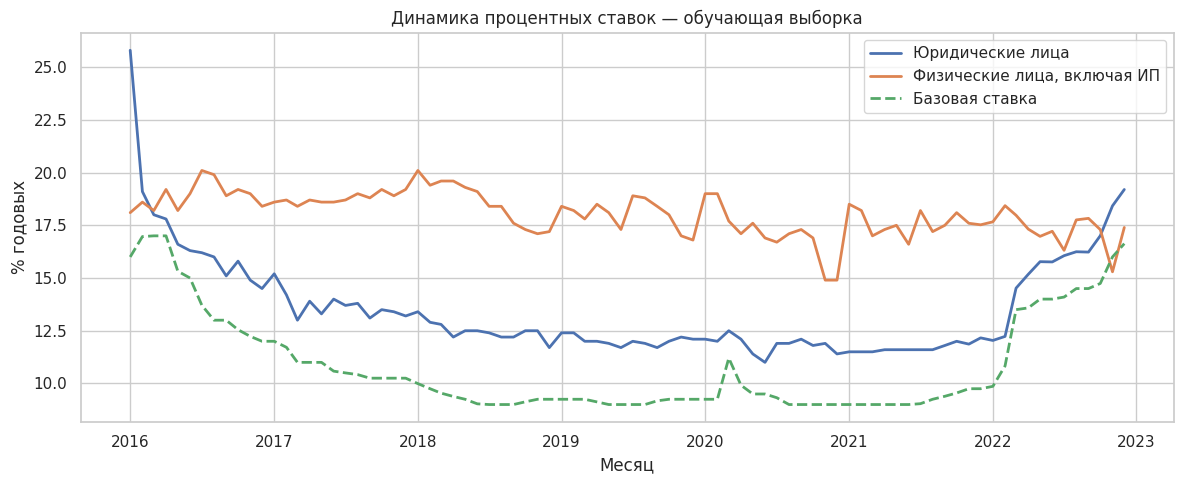

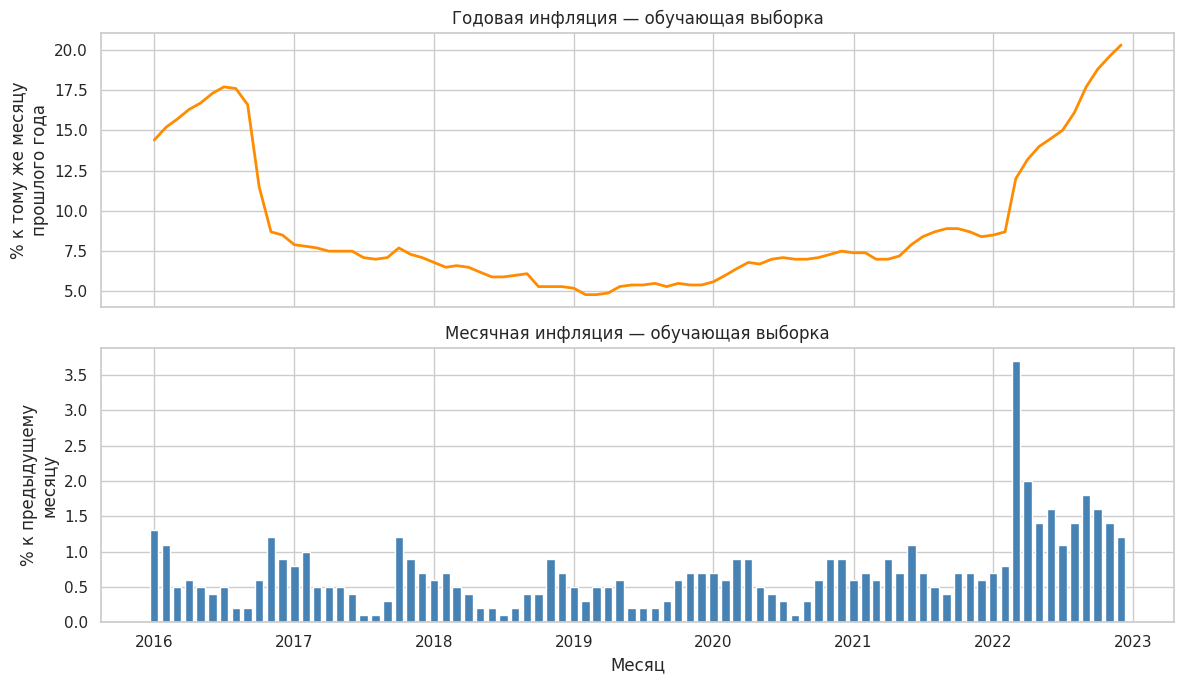

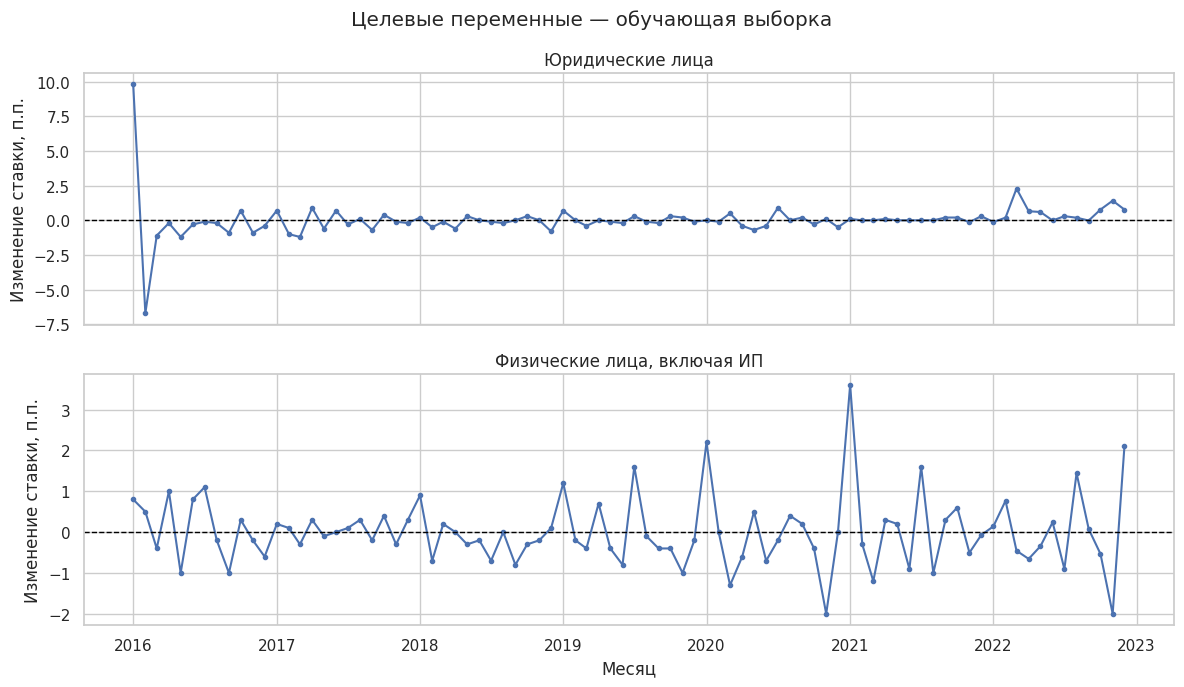

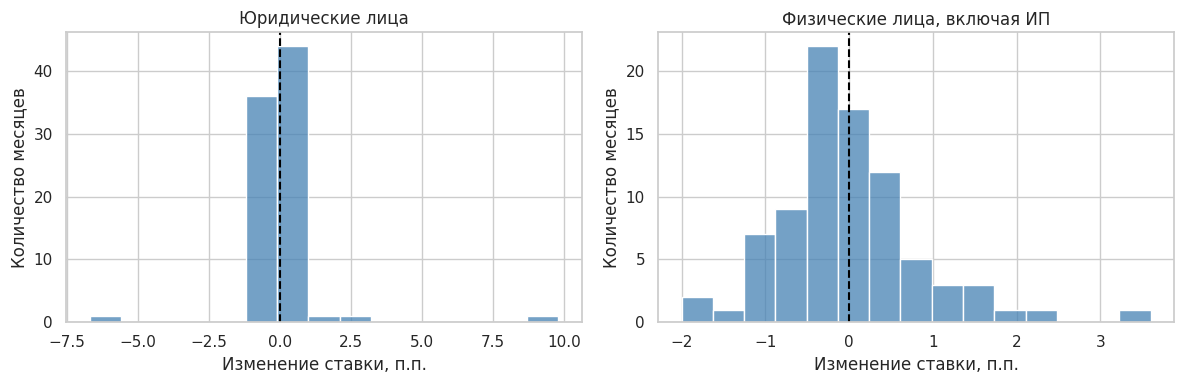

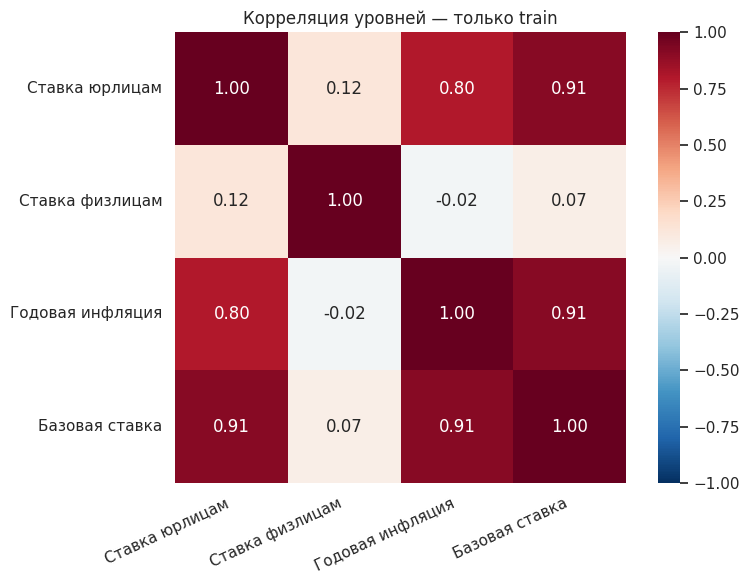

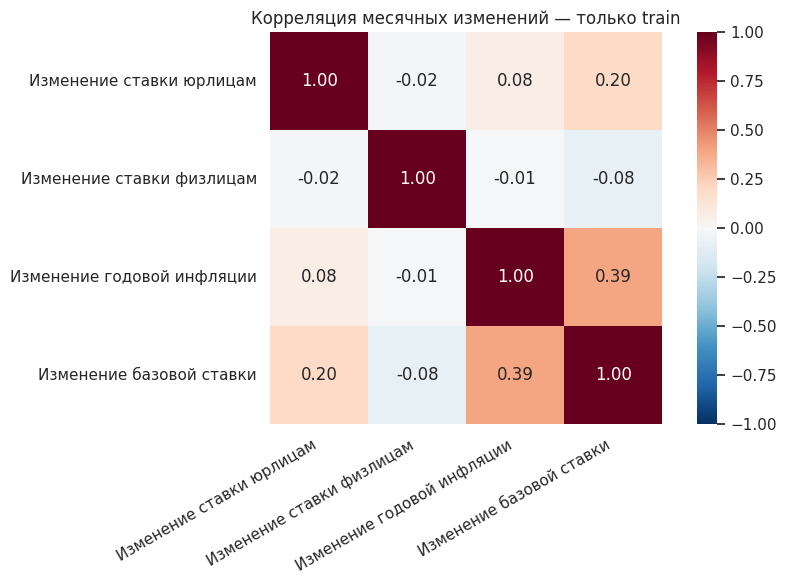

Проверка целевых переменных пройдена.

ЭТАП 1:
1. Данные загружены и проверены.
2. Типы, пропуски и смысл столбцов описаны.
3. Определены две целевые переменные.
4. Выполнено разделение 70% / 15% / 15% по времени.
5. Графики и корреляции рассчитаны только на train.
6. Риски утечки перечислены.

До моделирования необходимо уточнить доступность данных
на дату прогноза и зафиксировать допустимые лаги.


In [2]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if not (ROOT / "src").exists():
    raise RuntimeError("Сначала скачайте весь репозиторий и перейдите в его папку")
sys.path.insert(0, str(ROOT))
WORK = ROOT / "results/reproduced"
WORK.mkdir(parents=True, exist_ok=True)


from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

V6_RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)

print("Библиотеки подключены")

v6_path = (ROOT / "data/NBK_BNS_variant6_2016_2025.csv")

print("CSV-файлы в Colab:")
for file in (ROOT / "data").glob("*.csv"):
    print(file.name)

assert v6_path.exists(), (
    "Файл не найден. Загрузите NBK_BNS_variant6_2016_2025.csv "
    "в раздел «Файлы» слева."
)

print("\nНужный файл найден!")

v6_raw = pd.read_csv(v6_path, encoding="utf-8-sig")
v6_data = v6_raw.copy()

print("Количество строк:", len(v6_data))
print("Количество столбцов:", len(v6_data.columns))
print("\nНазвания столбцов:")
print(v6_data.columns.tolist())

v6_expected_columns = [
    "month",
    "loan_business_pct",
    "loan_households_pct",
    "inflation_mom_pct",
    "inflation_yoy_pct",
    "base_rate_pct",
    "Y_business_change_pp",
    "Y_households_change_pp",
]

assert set(v6_data.columns) == set(v6_expected_columns), (
    "Состав столбцов отличается от ожидаемого."
)

v6_data = v6_data[v6_expected_columns].copy()

print("Все необходимые столбцы присутствуют")

v6_data["month"] = pd.to_datetime(
    v6_data["month"],
    format="%Y-%m",
    errors="raise"
)

v6_data = (
    v6_data
    .sort_values("month")
    .reset_index(drop=True)
)

print("Начало периода:", v6_data["month"].min().strftime("%Y-%m"))
print("Конец периода:", v6_data["month"].max().strftime("%Y-%m"))

v6_numeric_columns = [
    column for column in v6_expected_columns
    if column != "month"
]

for column in v6_numeric_columns:
    v6_data[column] = pd.to_numeric(
        v6_data[column],
        errors="raise"
    )

assert np.isfinite(
    v6_data[v6_numeric_columns].to_numpy()
).all(), "Обнаружены пропуски или бесконечные значения."

print("Все показатели имеют корректный числовой формат")

v6_expected_months = pd.date_range(
    start="2016-01-01",
    end="2025-12-01",
    freq="MS"
)

v6_actual_months = pd.DatetimeIndex(v6_data["month"])

assert len(v6_data) == 120, "Ожидалось 120 месяцев."
assert not v6_data["month"].duplicated().any(), "Есть повторные месяцы."
assert v6_actual_months.equals(v6_expected_months), (
    "Есть пропущенные или неожиданные месяцы."
)

print("120 последовательных месяцев")
print("Повторных месяцев нет")
print("Пропущенных месяцев нет")

v6_n = len(v6_data)

v6_train_end = int(v6_n * 0.70)
v6_valid_end = int(v6_n * 0.85)

v6_train = v6_data.iloc[:v6_train_end].copy()
v6_valid = v6_data.iloc[v6_train_end:v6_valid_end].copy()
v6_test_locked = v6_data.iloc[v6_valid_end:].copy()

assert v6_train["month"].max() < v6_valid["month"].min()
assert v6_valid["month"].max() < v6_test_locked["month"].min()

print("Разделение выполнено без перемешивания")
print("Тестовая часть отложена до этапа 4")

v6_split_table = pd.DataFrame([
    {
        "Часть": name,
        "Месяцев": len(part),
        "Доля, %": len(part) / v6_n * 100,
        "Начало": part["month"].min().strftime("%Y-%m"),
        "Конец": part["month"].max().strftime("%Y-%m"),
    }
    for name, part in [
        ("Train — обучение", v6_train),
        ("Validation — настройка", v6_valid),
        ("Test — итоговая проверка", v6_test_locked),
    ]
])

display(v6_split_table)

v6_meanings = {
    "month": "Месяц наблюдения; не дата публикации",
    "loan_business_pct": "Ставка новых кредитов юрлицам в тенге, % годовых",
    "loan_households_pct": "Ставка новых кредитов физлицам, включая ИП, % годовых",
    "inflation_mom_pct": "Инфляция к предыдущему месяцу, %",
    "inflation_yoy_pct": "Инфляция к тому же месяцу прошлого года, %",
    "base_rate_pct": "Средняя базовая ставка за календарный месяц, % годовых",
    "Y_business_change_pp": "Изменение ставки юрлицам за месяц, п.п.",
    "Y_households_change_pp": "Изменение ставки физлицам за месяц, п.п.",
}

v6_dictionary = pd.DataFrame({
    "Столбец": v6_train.columns,
    "Тип": [str(v6_train[c].dtype) for c in v6_train.columns],
    "Пропуски в train, %": [
        v6_train[c].isna().mean() * 100
        for c in v6_train.columns
    ],
    "Экономический смысл": [
        v6_meanings[c] for c in v6_train.columns
    ],
})

display(v6_dictionary)

v6_targets = {
    "Юридические лица": "Y_business_change_pp",
    "Физические лица, включая ИП": "Y_households_change_pp",
}

v6_leakage_audit = pd.DataFrame([
    [
        "Кредитная ставка текущего месяца",
        "Входит в формулу текущего Y",
        "Не включать в X текущего месяца"
    ],
    [
        "Инфляция текущего месяца",
        "До публикации ещё неизвестна",
        "Использовать прошлые опубликованные значения"
    ],
    [
        "Средняя базовая ставка текущего месяца",
        "Полное среднее известно после окончания месяца",
        "Для прогноза использовать доступную прошлую информацию"
    ],
    [
        "Скользящие средние",
        "Могут случайно включить текущий или будущий месяц",
        "Рассчитывать только по прошлым доступным данным"
    ],
    [
        "Test",
        "Подбор модели по тесту завысит результат",
        "Использовать только на этапе 4"
    ],
], columns=["Показатель", "Риск", "Правило"])

display(v6_leakage_audit)

display(
    v6_train.head(10).round(3)
)

v6_descriptive = (
    v6_train[v6_numeric_columns]
    .describe()
    .T
    .rename(columns={
        "count": "Количество",
        "mean": "Среднее",
        "std": "Станд. отклонение",
        "min": "Минимум",
        "25%": "25-й процентиль",
        "50%": "Медиана",
        "75%": "75-й процентиль",
        "max": "Максимум",
    })
)

display(v6_descriptive.round(3))

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    v6_train["month"], v6_train["loan_business_pct"],
    label="Юридические лица", linewidth=2
)

ax.plot(
    v6_train["month"], v6_train["loan_households_pct"],
    label="Физические лица, включая ИП", linewidth=2
)

ax.plot(
    v6_train["month"], v6_train["base_rate_pct"],
    label="Базовая ставка", linewidth=2, linestyle="--"
)

ax.set_title("Динамика процентных ставок — обучающая выборка")
ax.set_xlabel("Месяц")
ax.set_ylabel("% годовых")
ax.legend()

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(
    v6_train["month"],
    v6_train["inflation_yoy_pct"],
    color="darkorange",
    linewidth=2
)
axes[0].set_title("Годовая инфляция — обучающая выборка")
axes[0].set_ylabel("% к тому же месяцу\nпрошлого года")

axes[1].bar(
    v6_train["month"],
    v6_train["inflation_mom_pct"],
    width=22,
    color="steelblue"
)
axes[1].set_title("Месячная инфляция — обучающая выборка")
axes[1].set_ylabel("% к предыдущему\nмесяцу")
axes[1].set_xlabel("Месяц")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

for ax, (group, target) in zip(axes, v6_targets.items()):
    ax.plot(
        v6_train["month"],
        v6_train[target],
        linewidth=1.5,
        marker="o",
        markersize=3
    )
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_title(group)
    ax.set_ylabel("Изменение ставки, п.п.")

axes[1].set_xlabel("Месяц")
fig.suptitle("Целевые переменные — обучающая выборка")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (group, target) in zip(axes, v6_targets.items()):
    sns.histplot(
        data=v6_train,
        x=target,
        bins=15,
        ax=ax,
        color="steelblue"
    )
    ax.axvline(0, color="black", linestyle="--")
    ax.set_title(group)
    ax.set_xlabel("Изменение ставки, п.п.")
    ax.set_ylabel("Количество месяцев")

plt.tight_layout()
plt.show()

v6_level_labels = {
    "loan_business_pct": "Ставка юрлицам",
    "loan_households_pct": "Ставка физлицам",
    "inflation_yoy_pct": "Годовая инфляция",
    "base_rate_pct": "Базовая ставка",
}

v6_level_corr = (
    v6_train[list(v6_level_labels)]
    .rename(columns=v6_level_labels)
    .corr()
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    v6_level_corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Корреляция уровней — только train")
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

v6_changes = pd.DataFrame({
    "Изменение ставки юрлицам":
        v6_train["Y_business_change_pp"],

    "Изменение ставки физлицам":
        v6_train["Y_households_change_pp"],

    "Изменение годовой инфляции":
        v6_train["inflation_yoy_pct"].diff(),

    "Изменение базовой ставки":
        v6_train["base_rate_pct"].diff(),
}).dropna()

plt.figure(figsize=(9, 6))

sns.heatmap(
    v6_changes.corr(),
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Корреляция месячных изменений — только train")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

for rate, target in [
    ("loan_business_pct", "Y_business_change_pp"),
    ("loan_households_pct", "Y_households_change_pp"),
]:
    calculated = v6_train[rate].diff()

    assert np.allclose(
        calculated.iloc[1:],
        v6_train[target].iloc[1:],
        atol=1e-8
    ), f"Ошибка расчёта {target}"

print("Проверка целевых переменных пройдена.")
print()
print("ЭТАП 1:")
print("1. Данные загружены и проверены.")
print("2. Типы, пропуски и смысл столбцов описаны.")
print("3. Определены две целевые переменные.")
print("4. Выполнено разделение 70% / 15% / 15% по времени.")
print("5. Графики и корреляции рассчитаны только на train.")
print("6. Риски утечки перечислены.")
print()
print("До моделирования необходимо уточнить доступность данных")
print("на дату прогноза и зафиксировать допустимые лаги.")